In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
import seaborn as sns

In [3]:
# Only get data Analyst jobs in the US
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country']=='United States')].copy()
# Drop NAN values from 'salary_year_avg' column for accurate visualisation
df_DA_US = df_DA_US.dropna(subset =['salary_year_avg'])
#explod out the column skill
df_DA_US = df_DA_US.explode('job_skills')




In [4]:
#Get the highest paying skills (order by highest to lowest)
df_DA_US_pay =df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count' , 'median']).sort_values(by ='median' , ascending = False)
df_DA_top_pay= df_DA_US_pay.head(10)
#get the highest paying skills (order by highest to lowest)
df_DA_US_skills=df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count' , 'median']).sort_values(by ='count' , ascending = False)
df_DA_skills = df_DS_US_skills.sort_values(by ='median' , ascending = False).head(10)

NameError: name 'df_DS_US_skills' is not defined

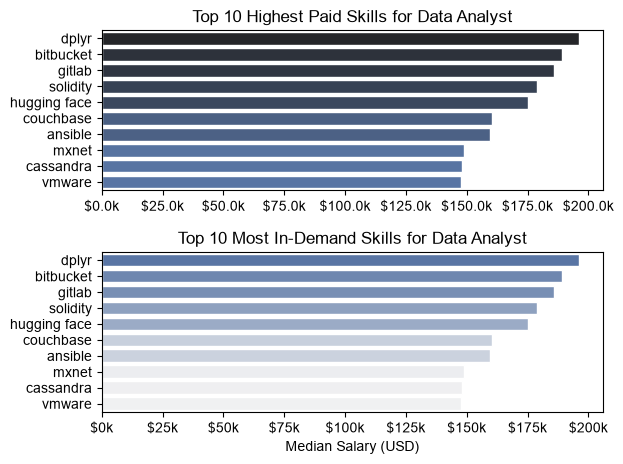

In [ ]:
# Top 10 Highest Paid Skills for Data Analyst
fig , ax = plt.subplots(2, 1)
sns.set_theme(style='ticks')
sns.barplot(df_DA_top_pay , x= 'median' , y= df_DA_top_pay.index, hue= 'median' , ax=ax[0], palette='dark:b_r')
ax[0].invert_yaxis()
ax[0].legend().remove()
ax[0].set_title('Top 10 Highest Paid Skills for Data Analyst')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].invert_yaxis()
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x , pos : f'${(int(x)/1000)}k'))

# Top 10 Most In-Demand Skills for Data Analyst
sns.barplot(df_DA_skills , x= 'median' , y=df_DA_skills.index , hue= 'median' , ax=ax[1], palette='light:b')
ax[1].legend().remove()
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analyst')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x , pos : f'${int(x/1000)}k'))

plt.tight_layout()
plt.show()

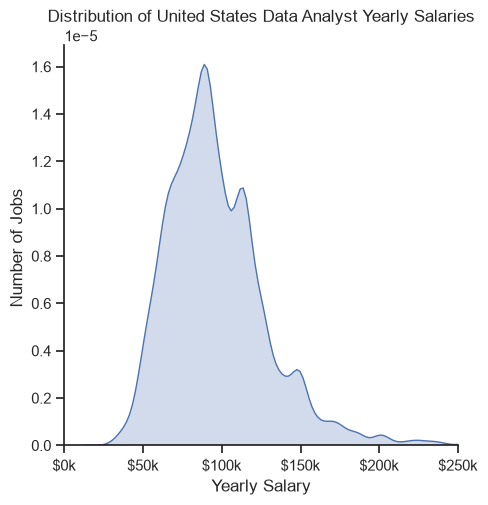

In [ ]:
sns.displot(df_DA_US['salary_year_avg'], kind = 'kde', fill = True)
plt.title('Distribution of United States Data Analyst Yearly Salaries')
plt.xlabel('Yearly Salary')
plt.ylabel('Number of Jobs ')
plt.xlim(0, 250000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}k'))
plt.show()

In [ ]:
# create 3 boxplots for Data Analyst, Data Engineer, and Data Scientist job salaries in the United States.
job_titles = [ 'Data Scientist','Data Analyst', 'Data Engineer'] #Create a list
# filtter the data to appropriate job_titles
df_US = df[(df['job_title_short'].isin(job_titles)) &(df['job_country']== 'United States')].copy()
#drop NAN values 
df_US = df_US.dropna(subset= ['salary_year_avg'])
## list of salaries for each job title
job_list = [df_US [df_US['job_title_short']== job_title]['salary_year_avg'] for job_title in job_titles]

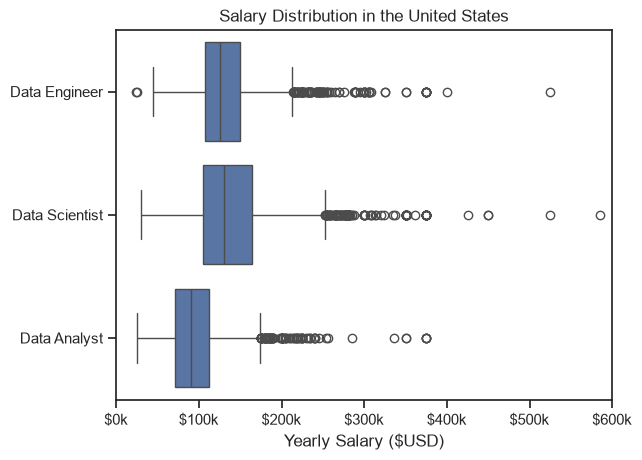

In [ ]:
sns.boxplot(data = df_US , x ='salary_year_avg' , y = 'job_title_short')
plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
plt.ylabel('')
plt.xlim(0, 600000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos :f'${int(x/1000)}k' ))
plt.show()